## Linear Regression and handling outliers

In [1]:
# Importing necessary libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Accessing the dataset

data=pd.read_csv('Melbourne_housing_FULL.csv')   
display(data)

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,68 Studley St,2,h,NaN,SS,Jellis,3/09/2016,2.5,3067.0,...,1.0,1.0,126.0,NaN,NaN,Yarra City Council,-37.80140,144.99580,Northern Metropolitan,4019.0
1,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,...,1.0,1.0,202.0,NaN,NaN,Yarra City Council,-37.79960,144.99840,Northern Metropolitan,4019.0
2,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,...,1.0,0.0,156.0,79.0,1900.0,Yarra City Council,-37.80790,144.99340,Northern Metropolitan,4019.0
3,Abbotsford,18/659 Victoria St,3,u,NaN,VB,Rounds,4/02/2016,2.5,3067.0,...,2.0,1.0,0.0,NaN,NaN,Yarra City Council,-37.81140,145.01160,Northern Metropolitan,4019.0
4,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,...,2.0,0.0,134.0,150.0,1900.0,Yarra City Council,-37.80930,144.99440,Northern Metropolitan,4019.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34852,Yarraville,13 Burns St,4,h,1480000.0,PI,Jas,24/02/2018,6.3,3013.0,...,1.0,3.0,593.0,NaN,NaN,Maribyrnong City Council,-37.81053,144.88467,Western Metropolitan,6543.0
34853,Yarraville,29A Murray St,2,h,888000.0,SP,Sweeney,24/02/2018,6.3,3013.0,...,2.0,1.0,98.0,104.0,2018.0,Maribyrnong City Council,-37.81551,144.88826,Western Metropolitan,6543.0
34854,Yarraville,147A Severn St,2,t,705000.0,S,Jas,24/02/2018,6.3,3013.0,...,1.0,2.0,220.0,120.0,2000.0,Maribyrnong City Council,-37.82286,144.87856,Western Metropolitan,6543.0
34855,Yarraville,12/37 Stephen St,3,h,1140000.0,SP,hockingstuart,24/02/2018,6.3,3013.0,...,NaN,NaN,NaN,NaN,NaN,Maribyrnong City Council,NaN,NaN,Western Metropolitan,6543.0


In [3]:
# Viewing the first 5 rows of the dataset

data.head()

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,68 Studley St,2,h,NaN,SS,Jellis,3/09/2016,2.5,3067.0,...,1.0,1.0,126.0,NaN,NaN,Yarra City Council,-37.8014,144.9958,Northern Metropolitan,4019.0
1,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,...,1.0,1.0,202.0,NaN,NaN,Yarra City Council,-37.7996,144.9984,Northern Metropolitan,4019.0
2,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,...,1.0,0.0,156.0,79.0,1900.0,Yarra City Council,-37.8079,144.9934,Northern Metropolitan,4019.0
3,Abbotsford,18/659 Victoria St,3,u,NaN,VB,Rounds,4/02/2016,2.5,3067.0,...,2.0,1.0,0.0,NaN,NaN,Yarra City Council,-37.8114,145.0116,Northern Metropolitan,4019.0
4,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,...,2.0,0.0,134.0,150.0,1900.0,Yarra City Council,-37.8093,144.9944,Northern Metropolitan,4019.0


In [4]:
# Checking the dimensions of the dataset

data.shape

(34857, 21)

In [5]:
# Checking the null values in the dataset 

data.isnull().sum()

Suburb               0
Address              0
Rooms                0
Type                 0
Price             7610
Method               0
SellerG              0
Date                 0
Distance             1
Postcode             1
Bedroom2          8217
Bathroom          8226
Car               8728
Landsize         11810
BuildingArea     21115
YearBuilt        19306
CouncilArea          3
Lattitude         7976
Longtitude        7976
Regionname           3
Propertycount        3
dtype: int64

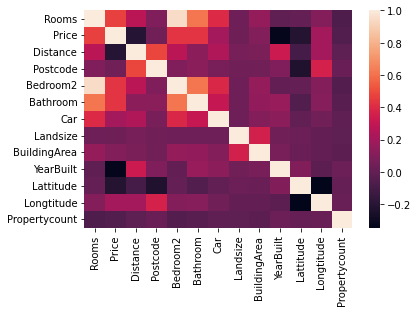

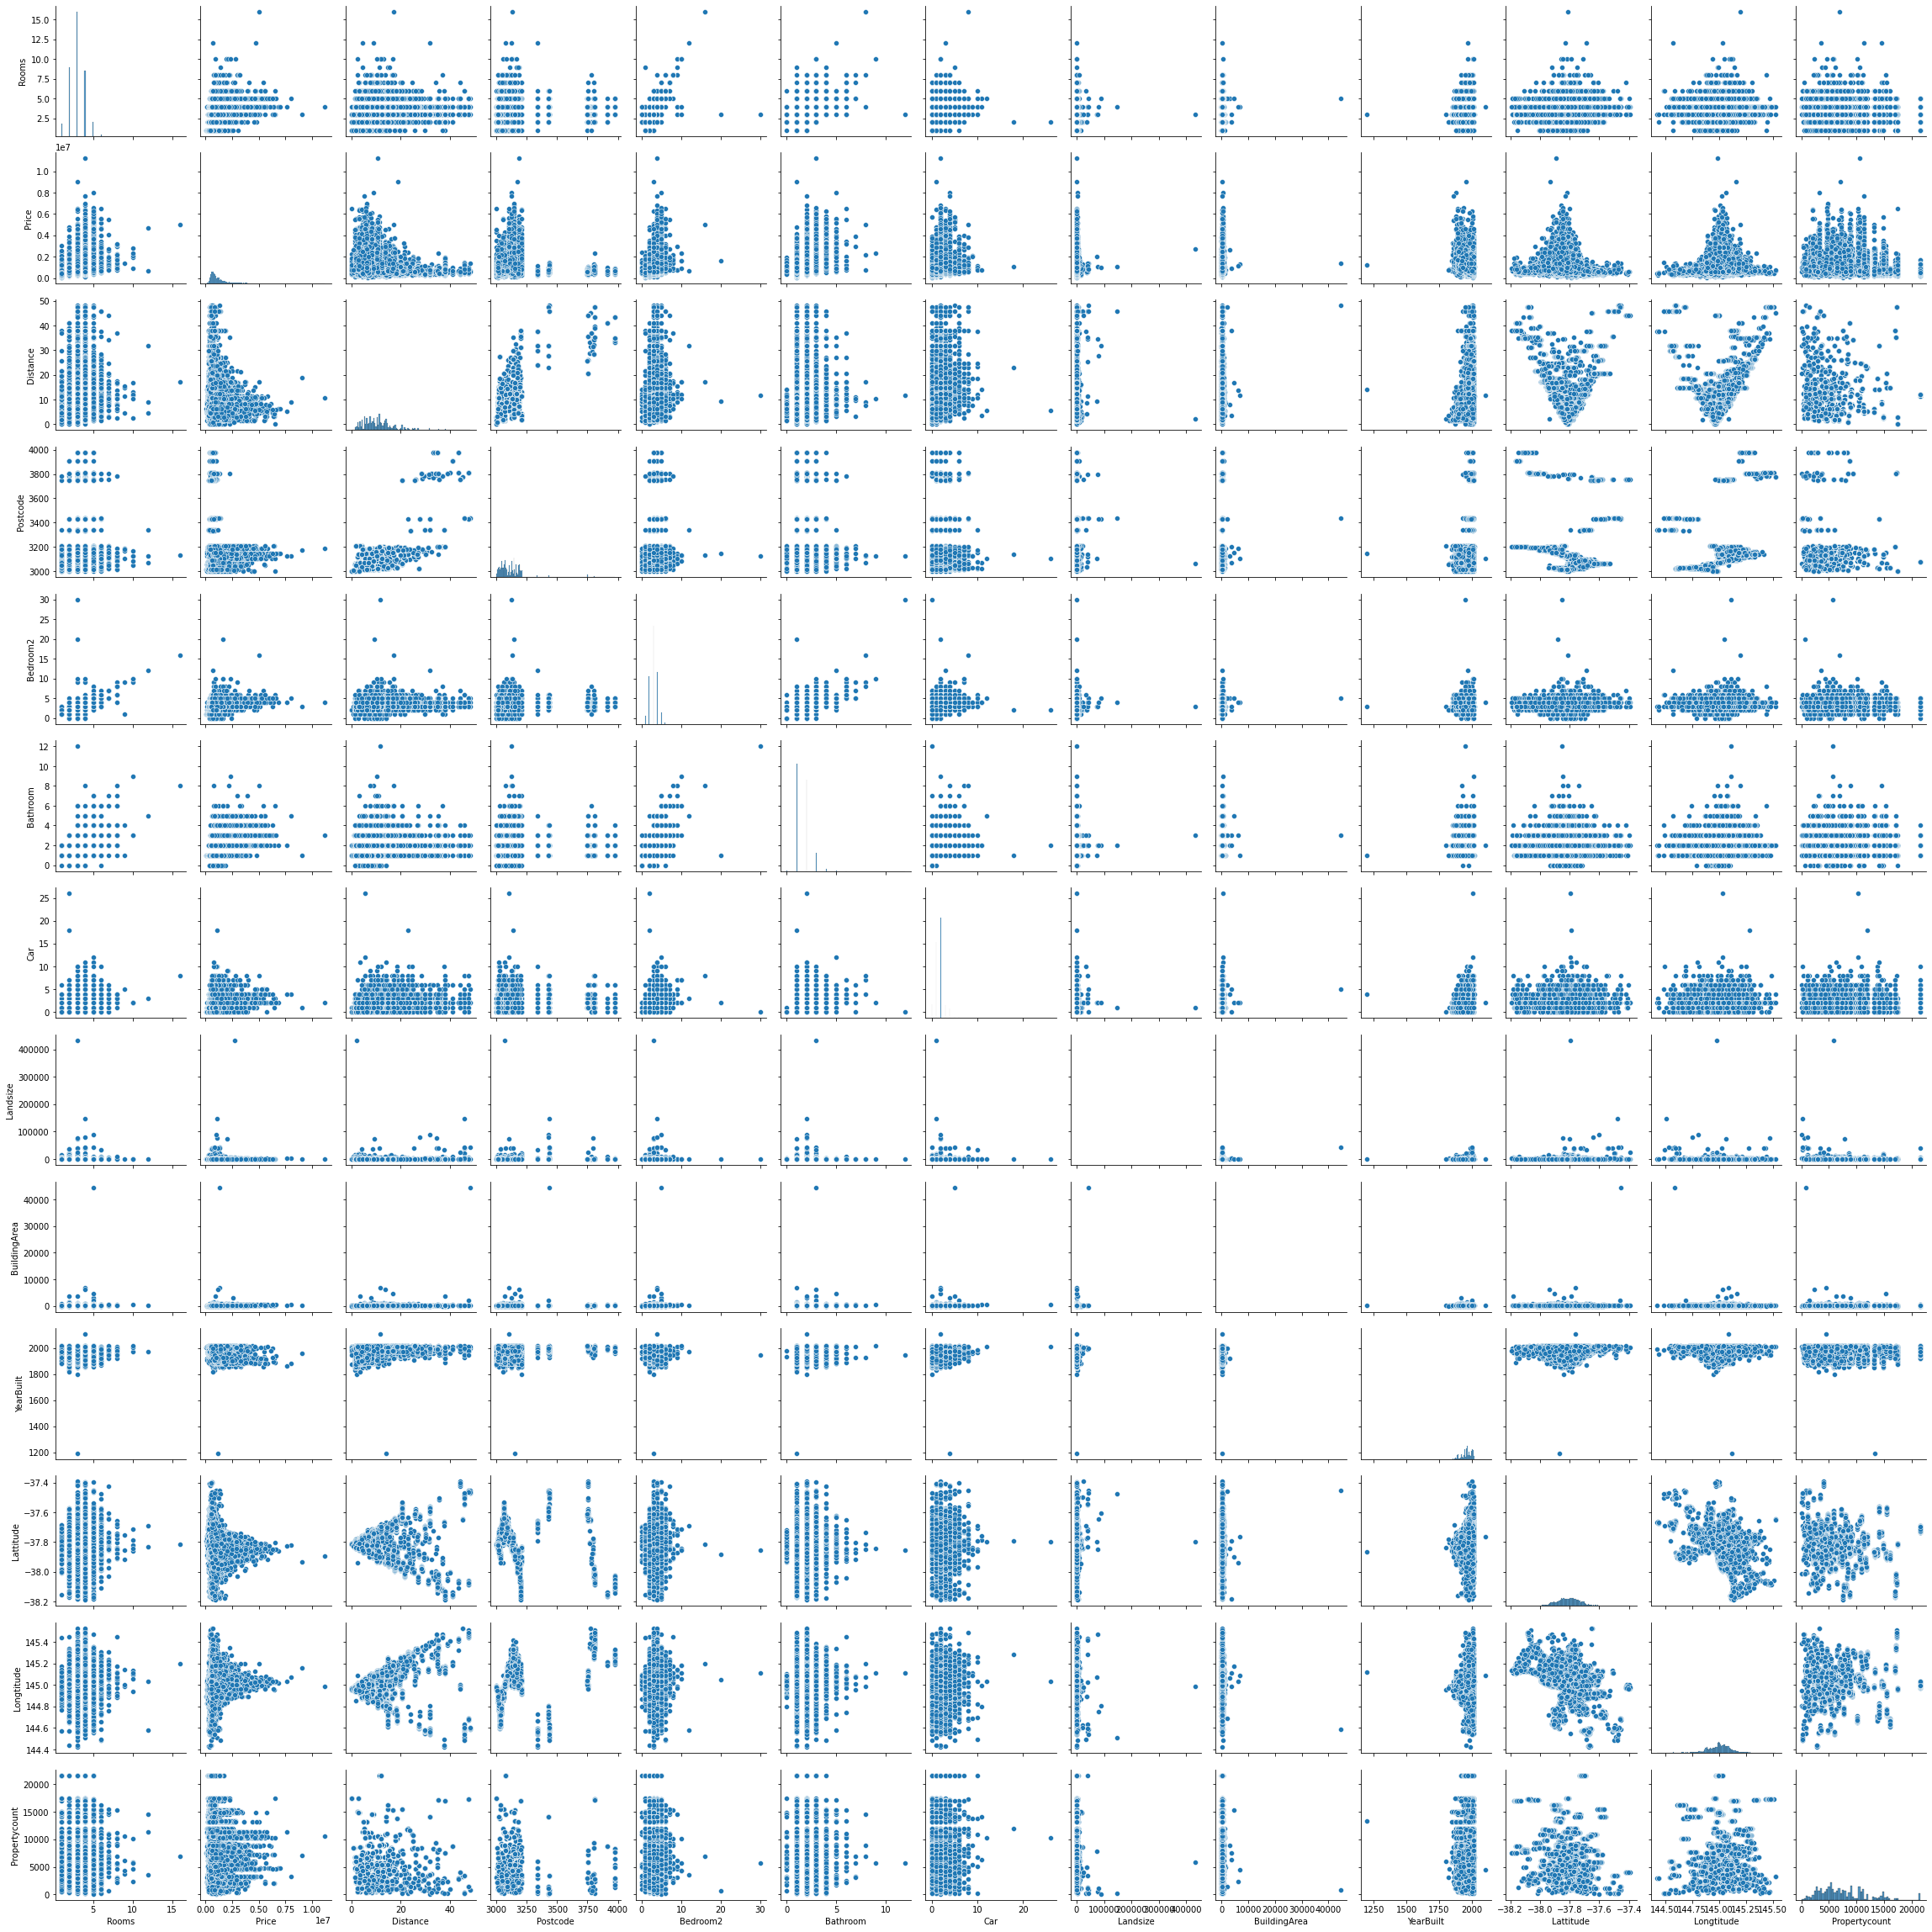

In [6]:
# Finding the correlation of variables to see which features can be eliminated

import seaborn as sns
corrMatrix=data.corr()
sns.heatmap(corrMatrix)
sns.pairplot(data)

In [7]:
# Dropping the unnecessary features

ndata=data.drop(['Address','Landsize','BuildingArea','Propertycount','Suburb','Type','Date','Regionname','CouncilArea','Method','SellerG','Longtitude','Lattitude','YearBuilt','Car','Postcode','Distance'],axis=1)
data=ndata

In [8]:
# Displaying the number of columns and rows in the new data

data.shape

(34857, 4)

In [9]:
# Displaying the first 5 rows of the new dataset

data.head()

,Rooms,Price,Bedroom2,Bathroom
0,2,NaN,2.0,1.0
1,2,1480000.0,2.0,1.0
2,2,1035000.0,2.0,1.0
3,3,NaN,3.0,2.0
4,3,1465000.0,3.0,2.0


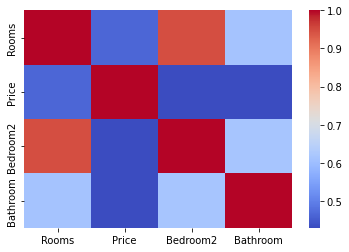

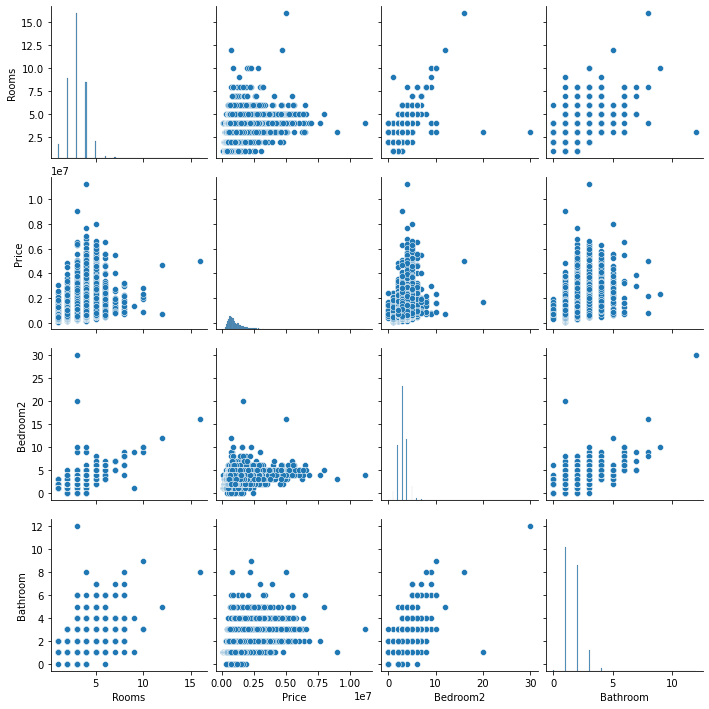

In [10]:
# Correlation between variables in the new dataset

corrMatrix=data.corr()
sns.heatmap(corrMatrix,cmap='coolwarm')
sns.pairplot(data)

In [11]:
# Handling missing values 

import math
a=data.Bedroom2.median()
b=math.floor(data.Price.mean())
c=data.Bathroom.median()
d=data.Rooms.median()
data['Bedroom2']=data['Bedroom2'].fillna(a).astype(int)
data['Price']=data['Price'].fillna(b).astype(int)
data['Bathroom']=data['Bathroom'].fillna(b).astype(int)
data['Rooms']=data['Rooms'].fillna(b).astype(int)
data.head()

,Rooms,Price,Bedroom2,Bathroom
0,2,1050173,2,1
1,2,1480000,2,1
2,2,1035000,2,1
3,3,1050173,3,2
4,3,1465000,3,2


In [12]:
# Rechecking for missing values

data.isnull().sum()

Rooms       0
Price       0
Bedroom2    0
Bathroom    0
dtype: int64

In [13]:
# Linear Regression with Outliers

In [14]:
# Setting the dependent and independent features

x=data[['Rooms', 'Bathroom','Bedroom2']]
y=data['Price']

In [15]:
# Splitting the data into training and testing data

from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=0)

In [16]:
# Traing the data

from sklearn.linear_model import LinearRegression
from sklearn import linear_model

linreg=LinearRegression()
linreg.fit(x_train,y_train)

LinearRegression()

In [17]:
# Predicting test results

y_pred=linreg.predict(x_test)
y_pred

array([ 827590.90683592,  827590.96424293,  827590.96424293, ...,
       1060225.93961149,  827590.96424293,  827590.96424293])

In [18]:
# Evaluating the Accuracy of the model

from sklearn.metrics import r2_score
Accuracy=r2_score(y_test,y_pred)*100
print(" Accuracy of the model is %.2f" %Accuracy)

 Accuracy of the model is 16.48


c:\users\agabith fernandes\appdata\local\programs\python\python39\lib\site-packages\seaborn\_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


<AxesSubplot:xlabel='Price'>

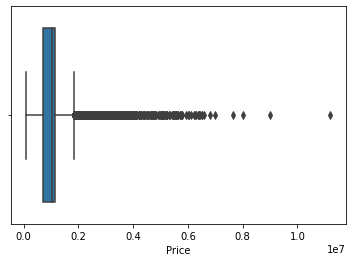

In [19]:
# Linear Regression without Outliers

# Checking for outliers in the 'Price' attribute which will be chosen for target variable

sns.boxplot(data['Price'])

In [20]:
# Removal of outlier

upper_limit1=data['Price'].quantile(0.90)
lower_limit1=data['Price'].quantile(0.10)

In [21]:
# Displaying outlier values

data[(data.Price < lower_limit1) | (data.Price > upper_limit1)]

,Rooms,Price,Bedroom2,Bathroom
11,3,1876000,4,2
17,1,300000,1,1
22,1,481000,3,1050173
26,4,1985000,3,1050173
27,1,500000,3,1050173
...,...,...,...,...
34837,5,2020000,5,3
34838,2,450000,3,1050173
34839,2,475000,3,1050173
34844,1,440000,3,1050173


In [22]:
# Removal of outliers

data['Price']=np.where(data["Price"]>=upper_limit1,upper_limit1,data['Price'])
data['Price']=np.where(data["Price"]<=lower_limit1,lower_limit1,data['Price'])

c:\users\agabith fernandes\appdata\local\programs\python\python39\lib\site-packages\seaborn\_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


<AxesSubplot:xlabel='Price'>

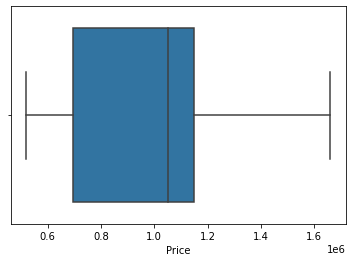

In [23]:
# Displaying the boxplot without outliers

sns.boxplot(data['Price'])

In [24]:
# Setting the dependent and independent features

x=data[['Rooms', 'Bathroom','Bedroom2']]
y=data['Price']

In [25]:
pip install -U scikit-learn scipy matplotlib

Requirement already up-to-date: scikit-learn in c:\users\agabith fernandes\appdata\local\programs\python\python39\lib\site-packages (1.1.1)Note: you may need to restart the kernel to use updated packages.


ERROR: Could not install packages due to an EnvironmentError: [WinError 5] Access is denied: 'c:\\users\\agabith fernandes\\appdata\\local\\programs\\python\\python39\\Lib\\site-packages\\matplotlib\\_c_internal_utils.cp39-win_amd64.pyd'
Consider using the `--user` option or check the permissions.

You should consider upgrading via the 'c:\users\agabith fernandes\appdata\local\programs\python\python39\python.exe -m pip install --upgrade pip' command.



Requirement already up-to-date: scipy in c:\users\agabith fernandes\appdata\local\programs\python\python39\lib\site-packages (1.8.1)
  Using cached matplotlib-3.5.2-cp39-cp39-win_amd64.whl (7.2 MB)


In [26]:
# Splitting the data into training and testing data

from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=0)

In [27]:
# Traing the data

from sklearn.linear_model import LinearRegression
from sklearn import linear_model

linreg=LinearRegression()
linreg.fit(x_train,y_train)

LinearRegression()

In [28]:
# Predicting test results

y_pred=linreg.predict(x_test)
y_pred

array([ 860832.59329834,  860832.64432793,  860832.64432793, ...,
       1003819.18001761,  860832.64432793,  860832.64432793])

In [29]:
# Evaluating the Accuracy of the model

from sklearn.metrics import r2_score
Accuracy=r2_score(y_test,y_pred)*100
print(" Accuracy of the model is %.2f" %Accuracy)

 Accuracy of the model is 17.87


## Lasso and Ridge 

In [30]:
# Importing necessary libraries

from sklearn.preprocessing import scale 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge, RidgeCV, Lasso, LassoCV
from sklearn.metrics import mean_squared_error

In [31]:
# Train and test score for linear model

train_score_lr = linreg.score(x_train, y_train)
test_score_lr = linreg.score(x_test, y_test)

print("The train score for linear model is {}".format(train_score_lr))
print("The test score for linear model is {}".format(test_score_lr))


# Ridge Regression Model

ridgeReg = Ridge(alpha=10)
ridgeReg.fit(x_train,y_train)

# Train and test score for ridge regression

train_score_ridge = ridgeReg.score(x_train, y_train)
test_score_ridge = ridgeReg.score(x_test, y_test)

print("\nRidge Model............................................\n")
print("The train score for ridge model is {}".format(train_score_ridge))
print("The test score for ridge model is {}".format(test_score_ridge))

# Lasso regression model

print("\nLasso Model............................................\n")
lasso = Lasso(alpha = 10)
lasso.fit(x_train,y_train)
train_score_ls =lasso.score(x_train,y_train)
test_score_ls =lasso.score(x_test,y_test)

print("The train score for ls model is {}".format(train_score_ls))
print("The test score for ls model is {}".format(test_score_ls))

The train score for linear model is 0.17927373860299955
The test score for linear model is 0.17874668150196582

Ridge Model............................................

The train score for ridge model is 0.17927363529945384
The test score for ridge model is 0.17875650287712663

Lasso Model............................................

The train score for ls model is 0.1792737271281427
The test score for ls model is 0.17875051147282317
